# Toy-box wave simulation: MATLAB-to-Python translation

This notebook is a single-file Python translation of the active execution path in two_d_sim_nwaves.m and its helper functions. It reproduces the 90-frame wavefield movie and MATLAB Figures 1, 2, 3, 55, 6, and 7.

The numerical defaults, units, FFT conventions, array order (z, x, time), and plotting limits match the MATLAB source. The original code does not seed its random generator; this notebook uses a fixed seed so a full run is reproducible. Change seed in SimulationConfig to obtain a new realization.

The MATLAB sections for Figures 8 and 9 occur after an unconditional return, so they are intentionally not part of the executed workflow. The supplied filter.mat.txt is a binary MATLAB v5 file despite its extension; a compact standard-library reader below loads its three double arrays without adding a SciPy dependency.

Every plot embeds the publication style used by the Time-Distance pipeline's k-omega diagrams: classic axes, 16-point external-LaTeX typography, inward major/minor ticks on all sides, cmr.fusion colors, centered spectral panels, and dedicated full-height colorbars. The local Time-Distance environment already provides CMasher and LaTeX.

In [1]:
# Configure the toy atmosphere and shared k-omega plotting helpers.

from dataclasses import dataclass
from pathlib import Path
from time import perf_counter
import struct
import warnings
import zlib
import xarray as xr

import numpy as np
import cmasher as cmr
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import Normalize, TwoSlopeNorm
from IPython.display import HTML, display
from numpy.fft import fft, fft2, fftfreq, fftshift, ifft

%matplotlib inline

np.set_printoptions(precision=6, suppress=True)

# Embed the Time-Distance pipeline's k-omega style so this notebook does not
# depend on the user's IPython startup profile. These are the effective settings
# used by Code/Time-Distance/plots.ipynb when its k-omega figures are produced.
plt.style.use("classic")
KOMEGA_STYLE = {
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": "Times New Roman",
    "axes.labelsize": 16,
    "font.size": 16,
    "legend.fontsize": 14,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "axes.titlesize": 16,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "legend.frameon": True,
    "legend.framealpha": 0.8,
    "axes.formatter.use_mathtext": True,
    "lines.linewidth": 2,
    "ytick.minor.visible": True,
    "xtick.minor.visible": True,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "savefig.dpi": 300,
    "pcolor.shading": "auto",
    "animation.embed_limit": 100.0,
}
mpl.rcParams.update(KOMEGA_STYLE)
mpl.rc("mathtext", default="regular")

KOMEGA_CMAP = cmr.fusion
KOMEGA_FILTER_CMAP = "viridis"
KOMEGA_FIGSIZE = (14.0, 9.0)
KOMEGA_WIDE_FIGSIZE = (14.0, 4.0)
KOMEGA_STACKED_FIGSIZE = (14.0, 16.0)
TARGET_PANEL_BOX_ASPECT = 1.55
KOMEGA_K_LIMITS = (0.0, 7.0)
KOMEGA_FREQUENCY_LIMITS_MHZ = (0.0, 10.0)
KOMEGA_PHASE_NORM = (-20.0, 0.0, 80.0)
PHASE_DIFFERENCE_LIMITS_MHZ = (-10.0, 10.0)
PHASE_DIFFERENCE_LIMITS_DEG = (-50.0, 50.0)
CROSS_CORRELATION_LIMITS_MIN = (-60.0, 60.0)


def zero_centered_norm(vmin, vmax):
    '''
    Purpose
    -------
    Use a zero-centered diverging normalization only when limits straddle zero.

    Inputs
    ------
    vmin, vmax: float
        Lower and upper data color limits.

    Outputs
    -------
    norm: matplotlib.colors.Normalize
        TwoSlopeNorm centered at zero when vmin < 0 < vmax; Normalize otherwise.
    '''
    # Use a diverging center only when zero lies strictly inside the data range
    if vmin < 0.0 < vmax:
        return TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)
    return Normalize(vmin=vmin, vmax=vmax)


def axis_edges_from_centers(values):
    '''
    Purpose
    -------
    Convert a regular one-dimensional coordinate vector to half-bin-padded outer edges.

    Inputs
    ------
    values: array-like
        At least two equally spaced centers in consistent physical units.

    Outputs
    -------
    lower, upper: tuple of float
        First/last center shifted outward by half the first bin spacing.
        Non-vector, undersized, and nonuniform inputs raise ValueError.
    '''
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or values.size < 2:
        raise ValueError("Image coordinates must contain at least two centers.")
    # Require uniform spacing before extending the outer centers by half a bin
    differences = np.diff(values)
    if not np.allclose(differences, differences[0]):
        raise ValueError("The active toy-box image grids must be regular.")
    half_step = differences[0] / 2.0
    return values[0] - half_step, values[-1] + half_step


def regular_grid_extent(x_centers, y_centers):
    '''
    Purpose
    -------
    Return the image extent from regular horizontal and vertical center vectors.

    Inputs
    ------
    x_centers, y_centers: array-like
        Regular one-dimensional plotting coordinates.

    Outputs
    -------
    extent: tuple
        Left, right, bottom, and top image edges in the input axis units.
    '''

    x_left, x_right = axis_edges_from_centers(x_centers)
    y_bottom, y_top = axis_edges_from_centers(y_centers)
    return x_left, x_right, y_bottom, y_top


def style_komega_axis(axis, box_aspect=TARGET_PANEL_BOX_ASPECT):
    '''
    Purpose
    -------
    Apply the production diagnostic-axis ticks, grid, and optional box aspect.

    Inputs
    ------
    axis: matplotlib.axes.Axes
        Axes updated in place.

    box_aspect: float or None, optional
        Panel height/width ratio; None leaves the box aspect unchanged.

    Outputs
    -------
    axis: matplotlib.axes.Axes
        The same styled axes object.
    '''
    axis.grid(False)
    axis.minorticks_on()
    axis.tick_params(which="both", direction="in", top=True, right=True)
    if box_aspect is not None:
        axis.set_box_aspect(box_aspect)
    return axis


def set_centered_figure_title(figure, title, y=0.98):
    '''
    Purpose
    -------
    Clear non-colorbar axis titles and create a centered figure title.

    Inputs
    ------
    figure: matplotlib.figure.Figure
        Figure whose axes titles are updated.

    title: str
        Figure title text.

    y: float, optional
        Title vertical position in normalized figure coordinates.

    Outputs
    -------
    title_artist: matplotlib.text.Text
        Figure suptitle placed at x = 0.5.
    '''
    for axis in figure.axes:
        if axis.get_label() != "<colorbar>":
            axis.set_title("")
    return figure.suptitle(title, x=0.5, y=y, ha="center")


def make_centered_single_panel_figure(
    figsize=KOMEGA_FIGSIZE,
    panel_bottom=0.10,
    panel_top=0.86,
    colorbar_width=0.022,
    colorbar_gap=0.012,
):
    '''
    Purpose
    -------
    Create one centered portrait diagnostic panel and an aligned colorbar axes.

    Inputs
    ------
    figsize: tuple of float, optional
        Figure width and height in inches.

    panel_bottom, panel_top: float, optional
        Panel vertical bounds in normalized figure coordinates.

    colorbar_width, colorbar_gap: float, optional
        Colorbar width and panel gap in normalized figure coordinates.

    Outputs
    -------
    figure, axis, colorbar_axis: tuple
        New Matplotlib figure, plotting axes, and reserved colorbar axes.
    '''
    figure = plt.figure(figsize=figsize)
    figure_width, figure_height = figure.get_size_inches()
    # Derive panel width from the target physical aspect before centering its colorbar
    panel_height = panel_top - panel_bottom
    panel_width = (
        panel_height * figure_height / (figure_width * TARGET_PANEL_BOX_ASPECT)
    )
    total_width = panel_width + colorbar_gap + colorbar_width
    panel_left = 0.5 - total_width / 2.0
    axis = figure.add_axes([panel_left, panel_bottom, panel_width, panel_height])
    colorbar_axis = figure.add_axes([
        panel_left + panel_width + colorbar_gap,
        panel_bottom,
        colorbar_width,
        panel_height,
    ])
    style_komega_axis(axis)
    return figure, axis, colorbar_axis


def make_wide_image_figure(
    figsize=KOMEGA_WIDE_FIGSIZE,
    data_width_to_height=5.0,
):
    '''
    Purpose
    -------
    Create a wide wavefield panel with a reserved colorbar axes.

    Inputs
    ------
    figsize: tuple of float, optional
        Figure width and height in inches.

    data_width_to_height: float, optional
        Desired physical panel width/height ratio.

    Outputs
    -------
    figure, axis, colorbar_axis: tuple
        New Matplotlib figure, plotting axes, and reserved colorbar axes.
    '''
    figure = plt.figure(figsize=figsize)
    figure_width, figure_height = figure.get_size_inches()
    panel_left, panel_width = 0.070, 0.82
    panel_height = (
        panel_width * figure_width / (figure_height * data_width_to_height)
    )
    panel_bottom = 0.16
    axis = figure.add_axes([panel_left, panel_bottom, panel_width, panel_height])
    colorbar_axis = figure.add_axes([0.905, panel_bottom, 0.018, panel_height])
    style_komega_axis(axis, box_aspect=None)
    return figure, axis, colorbar_axis


def make_centered_stacked_figure(
    figsize=KOMEGA_STACKED_FIGSIZE,
    panel_height=0.38,
    panel_gap=0.09,
    top_margin=0.96,
):
    '''
    Purpose
    -------
    Create two centered portrait panels with aligned colorbar axes.

    Inputs
    ------
    figsize: tuple of float, optional
        Figure width and height in inches.

    panel_height, panel_gap, top_margin: float, optional
        Panel height, vertical gap, and upper edge in normalized figure coordinates.

    Outputs
    -------
    figure, axes, colorbar_axes: tuple
        Figure and two aligned arrays of plotting/colorbar axes.
    '''
    figure = plt.figure(figsize=figsize)
    figure_width, figure_height = figure.get_size_inches()
    panel_width = (
        panel_height * figure_height / (figure_width * TARGET_PANEL_BOX_ASPECT)
    )
    colorbar_gap, colorbar_width = 0.012, 0.022
    total_width = panel_width + colorbar_gap + colorbar_width
    panel_left = 0.5 - total_width / 2.0
    # Allocate matched plotting and colorbar axes for the two stacked panels
    axes, colorbar_axes = [], []
    panel_bottoms = (
        top_margin - panel_height,
        top_margin - 2.0 * panel_height - panel_gap,
    )
    for panel_bottom in panel_bottoms:
        axis = figure.add_axes([panel_left, panel_bottom, panel_width, panel_height])
        colorbar_axis = figure.add_axes([
            panel_left + panel_width + colorbar_gap,
            panel_bottom,
            colorbar_width,
            panel_height,
        ])
        style_komega_axis(axis)
        axes.append(axis)
        colorbar_axes.append(colorbar_axis)
    return figure, np.asarray(axes), np.asarray(colorbar_axes)


def add_komega_colorbar(figure, mappable, colorbar_axis, label):
    '''
    Purpose
    -------
    Attach and style a labeled colorbar in its reserved axes.

    Inputs
    ------
    figure: matplotlib.figure.Figure
        Figure receiving the colorbar.

    mappable: matplotlib.cm.ScalarMappable
        Image or mesh defining the color scale.

    colorbar_axis: matplotlib.axes.Axes
        Reserved colorbar axes.

    label: str
        Colorbar quantity label with physical units.

    Outputs
    -------
    colorbar: matplotlib.colorbar.Colorbar
        Added colorbar with inward major/minor ticks.
    '''

    colorbar = figure.colorbar(mappable, cax=colorbar_axis)
    colorbar.set_label(label)
    colorbar.ax.minorticks_on()
    colorbar.ax.tick_params(which="both", direction="in")
    return colorbar


@dataclass(frozen=True)
class SimulationConfig:
    '''
    Purpose
    -------
    Store the toy wave-packet atmosphere, injection settings, domain, and random seed.

    Inputs
    ------
    injection: str, optional
        Use time_zero for one launch step; other values launch at every sampled time.

    nwaves: int, optional
        Upper random packet count per launch when greater than one; otherwise one.

    make_mirror, make_left_and_right: bool, optional
        Double packet counts/alternate signs, or randomly assign horizontal signs.

    acoustic_cutoff_mHz, sound_speed_km_s, gravity_cm_s2, tau_s: float, optional
        Atmospheric cutoff (mHz), sound speed (km/s), gravity (cm/s^2), and damping time (s).

    gamma: float, optional
        Dimensionless specific-heat ratio.

    lower_height_Mm, height_separation_Mm: float, optional
        Diagnostic heights in Mm.

    nx, nz, nt: int, optional
        Horizontal, vertical, and temporal sample counts.

    xmax_Mm, zmax_Mm, tmax_minutes: float, optional
        Domain extents in Mm and duration in minutes.

    sigma_x_Mm, sigma_z_Mm: float, optional
        Gaussian packet width parameters in Mm, as used in exp(-((x-center)/sigma)**2).

    amplitude: float, optional
        Overall synthesized-field amplitude in the chosen field units.

    seed: int, optional
        Seed for the NumPy random generator.

    Outputs
    -------
    config: SimulationConfig
        Frozen simulation settings; construction does not run a simulation.
    '''

    injection: str = "all_times"
    nwaves: int = 10
    make_mirror: bool = False
    make_left_and_right: bool = True
    acoustic_cutoff_mHz: float = 5.3
    sound_speed_km_s: float = 6.5
    gamma: float = 5.0 / 3.0
    gravity_cm_s2: float = 274.0e2
    tau_s: float = 500.0
    lower_height_Mm: float = 1.0
    height_separation_Mm: float = 0.350
    nx: int = 128
    nz: int = 512
    nt: int = 90
    xmax_Mm: float = 25.0
    zmax_Mm: float = 5.0
    tmax_minutes: float = 90.0
    sigma_x_Mm: float = 1.0
    sigma_z_Mm: float = 0.5
    amplitude: float = 1.0
    seed: int = 20250831


config = SimulationConfig()
config

SimulationConfig(injection='all_times', nwaves=10, make_mirror=False, make_left_and_right=True, acoustic_cutoff_mHz=5.3, sound_speed_km_s=6.5, gamma=1.6666666666666667, gravity_cm_s2=27400.0, tau_s=500.0, lower_height_Mm=1.0, height_separation_Mm=0.35, nx=128, nz=512, nt=90, xmax_Mm=25.0, zmax_Mm=5.0, tmax_minutes=90.0, sigma_x_Mm=1.0, sigma_z_Mm=0.5, amplitude=1.0, seed=20250831)

## Load the wave-number/frequency sampling filter

The path search supports running the notebook either from this directory or from the repository root. The raw filter is plotted later; its cube is the probability surface used by the MATLAB pinky sampler.

In [2]:
# Locate and decode the MATLAB probability-filter arrays.

def locate_filter_file():
    '''
    Purpose
    -------
    Search the current directory and its parents for a recognized MATLAB filter file.

    Inputs
    ------
    None

    Outputs
    -------
    path: Path
        First existing candidate filter.mat.txt/filter.mat path. Raise
        FileNotFoundError when no candidate exists in the search roots.
    '''

    relative_candidates = (
        Path("filter.mat.txt"),
        Path("filter.mat"),
        Path("DATA") / "filter.mat",
        Path("Code") / "Toy-Box-Simulation" / "filter.mat.txt",
    )
    for base in (Path.cwd(), *Path.cwd().parents):
        for relative_path in relative_candidates:
            candidate = (base / relative_path).resolve()
            if candidate.is_file():
                return candidate
    raise FileNotFoundError(
        "Could not locate filter.mat.txt. Run this notebook from its own directory "
        "or from the Morales_2025a repository."
    )


def _mat_v5_element(buffer, offset, endian):
    '''
    Purpose
    -------
    Decode one standard or small MATLAB v5 binary data-element envelope.

    Inputs
    ------
    buffer: bytes or memoryview
        Binary input containing the element.

    offset: int
        Starting byte offset.

    endian: str
        Struct byte-order prefix, < or >.

    Outputs
    -------
    data_type, payload, next_offset: tuple
        Numeric MATLAB type, payload memoryview, and next padded element offset.
        Truncated envelopes/payloads and invalid small-element sizes raise ValueError.
    '''
    if offset + 8 > len(buffer):
        raise ValueError("Truncated MATLAB v5 data element.")
    # Distinguish compact tags from standard byte-count/payload envelopes
    first_word, second_word = struct.unpack_from(endian + "II", buffer, offset)
    small_nbytes = first_word >> 16
    if small_nbytes:
        data_type = first_word & 0xFFFF
        if small_nbytes > 4:
            raise ValueError("Invalid small-data-element size.")
        return data_type, memoryview(buffer)[offset + 4:offset + 4 + small_nbytes], offset + 8

    data_type = first_word
    data_start = offset + 8
    data_end = data_start + second_word
    if data_end > len(buffer):
        raise ValueError("Truncated MATLAB v5 payload.")
    padded_end = data_start + ((second_word + 7) // 8) * 8
    return data_type, memoryview(buffer)[data_start:data_end], padded_end


def _mat_v5_matrix(payload, endian):
    '''
    Purpose
    -------
    Decode one real MATLAB mxDOUBLE_CLASS matrix payload.

    Inputs
    ------
    payload: bytes or memoryview
        miMATRIX contents containing flags, dimensions, name, and real values.

    endian: str
        Little- or big-endian prefix, < or >.

    Outputs
    -------
    name, values: tuple
        UTF-8 array name and copied float array with the stored dimensions
        reconstructed in Fortran order. Unsupported types or sizes raise ValueError.
    '''
    offset = 0
    flags_type, flags, offset = _mat_v5_element(payload, offset, endian)
    dims_type, dims_bytes, offset = _mat_v5_element(payload, offset, endian)
    name_type, name_bytes, offset = _mat_v5_element(payload, offset, endian)
    real_type, real_bytes, offset = _mat_v5_element(payload, offset, endian)

    if flags_type != 6 or dims_type != 5 or real_type != 9:
        raise ValueError("Expected a real double MATLAB matrix.")
    array_flags = np.frombuffer(flags, dtype=endian + "u4")
    if (int(array_flags[0]) & 0xFF) != 6:
        raise ValueError("Expected MATLAB mxDOUBLE_CLASS data.")

    # Reconstruct MATLAB column-major storage using the declared dimensions
    dimensions = tuple(int(value) for value in np.frombuffer(dims_bytes, dtype=endian + "i4"))
    name = bytes(name_bytes).decode("utf-8")
    values = np.frombuffer(real_bytes, dtype=endian + "f8")
    if values.size != int(np.prod(dimensions)):
        raise ValueError(f"MATLAB matrix {name!r} has inconsistent dimensions.")
    return name, values.reshape(dimensions, order="F").astype(float, copy=True)


def load_matlab_v5_doubles(path):
    '''
    Purpose
    -------
    Load real double arrays from uncompressed or compressed MATLAB v5 elements.

    Inputs
    ------
    path: str or Path
        MAT-file read as a complete byte buffer.

    Outputs
    -------
    arrays: dict of str to np.ndarray
        Decoded named matrices. Invalid headers/endian flags, unsupported
        element types, truncated data, and decompression failures propagate.
    '''
    raw = Path(path).read_bytes()
    if len(raw) < 128 or not raw.startswith(b"MATLAB 5.0 MAT-file"):
        raise ValueError("This is not a MATLAB v5 MAT-file.")
    byte_order = raw[126:128]
    endian = "<" if byte_order == b"IM" else ">" if byte_order == b"MI" else None
    if endian is None:
        raise ValueError("Unrecognized MATLAB v5 endian indicator.")

    # Decode top-level matrices, expanding compressed streams before reading inner matrices
    arrays = {}
    offset = 128
    while offset + 8 <= len(raw):
        data_type, payload, offset = _mat_v5_element(raw, offset, endian)
        if data_type == 15:
            inner = zlib.decompress(payload)
            inner_offset = 0
            while inner_offset + 8 <= len(inner):
                inner_type, inner_payload, inner_offset = _mat_v5_element(
                    inner, inner_offset, endian
                )
                if inner_type != 14:
                    raise ValueError("Expected miMATRIX inside miCOMPRESSED data.")
                name, array = _mat_v5_matrix(inner_payload, endian)
                arrays[name] = array
        elif data_type == 14:
            name, array = _mat_v5_matrix(payload, endian)
            arrays[name] = array
        else:
            raise ValueError(f"Unsupported top-level MATLAB data type {data_type}.")
    return arrays


filter_path = locate_filter_file()
mat_data = load_matlab_v5_doubles(filter_path)
k_filter = np.asarray(mat_data["k"], dtype=float).ravel()
f_filter = np.asarray(mat_data["f"], dtype=float).ravel()
filter_surface = np.asarray(mat_data["filt"], dtype=float)

if filter_surface.shape != (f_filter.size, k_filter.size):
    raise ValueError("Expected filt rows=f and columns=k.")
if np.any(filter_surface < 0.0):
    raise ValueError("The sampling filter must be nonnegative.")

print(f"Loaded {filter_path}")
print(
    f"filter shape={filter_surface.shape}, "
    f"k=[{k_filter.min():.6g}, {k_filter.max():.6g}] 1/Mm, "
    f"f=[{f_filter.min():.6g}, {f_filter.max():.6g}] mHz"
)

Loaded /Users/juliomorales/Library/CloudStorage/GoogleDrive-juliomorales1823@gmail.com/My Drive/Graduate School/Research/Projects/Helioseismology/Morales_2025a/Code/Toy-Box-Simulation/filter.mat.txt
filter shape=(420, 80), k=[0, 7.12901] 1/Mm, f=[0, 42.0374] mHz


## Numerical translation of pinky, script_kz, and make_nwaves

PinkySampler preserves the two-stage MATLAB draw: a PCHIP-refined marginal draw in k followed by a PCHIP-refined conditional draw in frequency. Wave packets are nominally launched at individual time samples, but the source applies no causal mask; each packet therefore contributes at all modeled times, including before its launch time. That behavior is preserved exactly.

In [3]:
# Define PCHIP sampling and the damped vertical-wave properties.

def pchip_interpolate(x, y, x_new):
    '''
    Purpose
    -------
    Evaluate the shape-preserving cubic Hermite interpolant on the original data interval.

    Inputs
    ------
    x, y: array-like
        Equal-length one-dimensional coordinates and values, with at least two
        points and strictly increasing x.

    x_new: array-like
        Evaluation coordinates lying inside the original x interval.

    Outputs
    -------
    values: np.ndarray
        Interpolated y with the shape of x_new and y units. Invalid data
        dimensions, nonincreasing coordinates, and extrapolation raise ValueError.
    '''
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x_new = np.asarray(x_new, dtype=float)
    if x.ndim != 1 or y.ndim != 1 or x.size != y.size or x.size < 2:
        raise ValueError("pchip_interpolate expects equal-length 1-D x/y arrays.")
    # Calculate interval widths and secant slopes before limiting endpoint derivatives
    h = np.diff(x)
    if np.any(h <= 0.0):
        raise ValueError("PCHIP x values must be strictly increasing.")
    slopes = np.diff(y) / h
    derivatives = np.zeros_like(y)

    if x.size == 2:
        derivatives[:] = slopes[0]
    else:
        same_sign = (slopes[:-1] != 0.0) & (slopes[1:] != 0.0) & (
            np.sign(slopes[:-1]) == np.sign(slopes[1:])
        )
        weight1 = 2.0 * h[1:] + h[:-1]
        weight2 = h[1:] + 2.0 * h[:-1]
        derivatives[1:-1][same_sign] = (
            (weight1[same_sign] + weight2[same_sign])
            / (
                weight1[same_sign] / slopes[:-1][same_sign]
                + weight2[same_sign] / slopes[1:][same_sign]
            )
        )

        def edge_derivative(h0, h1, slope0, slope1):
            '''
            Purpose
            -------
            Limit a one-sided PCHIP endpoint derivative to preserve local shape.

            Inputs
            ------
            h0, h1: float
                First and second adjacent interval widths.

            slope0, slope1: float
                Corresponding adjacent secant slopes.

            Outputs
            -------
            derivative: float
                One-sided derivative clipped to zero or three times the endpoint
                slope when needed to preserve monotonicity.
            '''

            derivative = ((2.0 * h0 + h1) * slope0 - h0 * slope1) / (h0 + h1)
            if np.sign(derivative) != np.sign(slope0):
                return 0.0
            if np.sign(slope0) != np.sign(slope1) and abs(derivative) > 3.0 * abs(slope0):
                return 3.0 * slope0
            return derivative

        derivatives[0] = edge_derivative(h[0], h[1], slopes[0], slopes[1])
        derivatives[-1] = edge_derivative(h[-1], h[-2], slopes[-1], slopes[-2])

    # Reject extrapolation before evaluating the local Hermite basis
    if np.any(x_new < x[0]) or np.any(x_new > x[-1]):
        raise ValueError("This notebook does not require PCHIP extrapolation.")
    interval = np.searchsorted(x, x_new, side="right") - 1
    interval = np.clip(interval, 0, x.size - 2)
    local_h = h[interval]
    t = (x_new - x[interval]) / local_h
    t2 = t * t
    t3 = t2 * t
    return (
        (2.0 * t3 - 3.0 * t2 + 1.0) * y[interval]
        + (t3 - 2.0 * t2 + t) * local_h * derivatives[interval]
        + (-2.0 * t3 + 3.0 * t2) * y[interval + 1]
        + (t3 - t2) * local_h * derivatives[interval + 1]
    )


def normalized_cdf(weights):
    '''
    Purpose
    -------
    Construct a normalized cumulative distribution from nonnegative weights.

    Inputs
    ------
    weights: array-like
        Probability weights; tiny negative roundoff is clipped to zero.

    Outputs
    -------
    cdf: np.ndarray
        Flattened cumulative probabilities ending at exactly one. Materially
        negative weights or a nonfinite/nonpositive total raise ValueError.
    '''

    weights = np.asarray(weights, dtype=float)
    scale = np.max(np.abs(weights)) if weights.size else 0.0
    tolerance = 100.0 * np.finfo(float).eps * max(1.0, scale)
    if np.any(weights < -tolerance):
        raise ValueError("Interpolation produced a materially negative probability.")
    # Remove insignificant negative roundoff before normalizing cumulative weights
    weights = np.clip(weights, 0.0, None)
    total = weights.sum()
    if not np.isfinite(total) or total <= 0.0:
        raise ValueError("Probability weights must have a finite positive sum.")
    cdf = np.cumsum(weights / total)
    cdf[-1] = 1.0
    return cdf


def draw_from_cdf(cdf, rng):
    '''
    Purpose
    -------
    Draw one discrete index from a normalized cumulative distribution.

    Inputs
    ------
    cdf: array-like
        Increasing cumulative probabilities ending at one.

    rng: numpy.random.Generator
        Generator supplying one uniform random draw.

    Outputs
    -------
    index: int
        First right-side cumulative insertion index, clamped to the final bin.
    '''

    return min(np.searchsorted(cdf, rng.random(), side="right"), len(cdf) - 1)


class PinkySampler:
    '''
    Purpose
    -------
    Cache refined marginal and conditional CDFs for MATLAB-style two-dimensional sampling.

    Inputs
    ------
    x_values, y_values: array-like
        Increasing original coordinate vectors.

    distribution: array-like
        Nonnegative weights with shape (len(y_values), len(x_values)).

    resolution: float, optional
        Refined-grid multiplier greater than one.

    Outputs
    -------
    sampler: PinkySampler
        Cached PCHIP-based distributions; sample() returns coordinate pairs.
    '''

    def __init__(self, x_values, y_values, distribution, resolution=2):
        '''
        Purpose
        -------
        Refine the marginal/conditional probability grids and cache their cumulative distributions.

        Inputs
        ------
        x_values, y_values: array-like
            Increasing original coordinate vectors.

        distribution: array-like
            Nonnegative weights in (y, x) order.

        resolution: float, optional
            Multiplier greater than one for both refined coordinate counts.

        Outputs
        -------
        None
            Store refined axes and CDFs. Reject incompatible shapes/negative
            weights; negative marginal interpolation roundoff uses abs() with a warning.
        '''

        self.x = np.asarray(x_values, dtype=float)
        self.y = np.asarray(y_values, dtype=float)
        self.distribution = np.asarray(distribution, dtype=float)
        if self.distribution.shape != (self.y.size, self.x.size):
            raise ValueError("Distribution dimensions must be (len(y), len(x)).")
        if np.any(self.distribution < 0.0):
            raise ValueError("All probability values must be nonnegative.")
        if resolution <= 1:
            raise ValueError("resolution must be greater than one.")

        self.x_refined = np.linspace(self.x.min(), self.x.max(), round(resolution * self.x.size))
        self.y_refined = np.linspace(self.y.min(), self.y.max(), round(resolution * self.y.size))

        # Refine the x marginal first, then cache conditional y CDFs at every refined x
        column_marginal = self.distribution.sum(axis=0)
        refined_marginal = pchip_interpolate(self.x, column_marginal, self.x_refined)
        if np.any(refined_marginal < 0.0):
            warnings.warn("PCHIP generated negative marginal weights; matching MATLAB abs().")
            refined_marginal = np.abs(refined_marginal)
        self.x_cdf = normalized_cdf(refined_marginal)

        self.y_cdfs = np.empty((self.x_refined.size, self.y_refined.size), dtype=float)
        epsilon = np.finfo(float).eps
        # Interpolate each conditional between the nearest original x columns
        for refined_index, x0 in enumerate(self.x_refined):
            distance_squared = (x0 - self.x) ** 2
            nearest = np.argsort(distance_squared)[:2]
            if distance_squared[nearest[0]] < epsilon:
                conditional = self.distribution[:, nearest[0]]
            else:
                low, high = np.sort(nearest)
                x_low, x_high = self.x[low], self.x[high]
                weight_low = 1.0 - (x0 - x_low) / (x_high - x_low)
                weight_high = 1.0 - (x_high - x0) / (x_high - x_low)
                conditional = (
                    weight_low * self.distribution[:, low]
                    + weight_high * self.distribution[:, high]
                )
            refined_conditional = pchip_interpolate(self.y, conditional, self.y_refined)
            if refined_conditional.sum() > 0.0:
                self.y_cdfs[refined_index] = normalized_cdf(refined_conditional)
            else:
                # Zero-marginal k bins can never be sampled; provide a valid sentinel CDF.
                self.y_cdfs[refined_index] = np.linspace(
                    1.0 / self.y_refined.size, 1.0, self.y_refined.size
                )

    def sample(self, rng):
        '''
        Purpose
        -------
        Sample one refined x coordinate and its conditional y coordinate.

        Inputs
        ------
        rng: numpy.random.Generator
            Random generator used for both cumulative-distribution draws.

        Outputs
        -------
        x, y: tuple of float
            Sampled coordinates in the original axis units.
        '''

        x_index = draw_from_cdf(self.x_cdf, rng)
        y_index = draw_from_cdf(self.y_cdfs[x_index], rng)
        return self.x_refined[x_index], self.y_refined[y_index]


def vertical_wave_properties(kx_Mm_inv, frequency_mHz, cfg):
    '''
    Purpose
    -------
    Evaluate the radiatively damped vertical-wave relation with explicit cgs conversion.

    Inputs
    ------
    kx_Mm_inv: array-like
        Signed horizontal angular wavenumber in Mm^-1.

    frequency_mHz: array-like
        Cyclic frequency in mHz; arrays follow NumPy broadcasting.

    cfg: SimulationConfig
        Atmospheric gravity (cm/s^2), sound speed (km/s), cutoff (mHz), gamma,
        and radiative relaxation time (s).

    Outputs
    -------
    properties: dict
        Angular frequency (rad/s), negative-real kz and imaginary/kappa terms
        (Mm^-1), phase/group speeds (Mm/s), scale height (cm), and buoyancy
        frequency (rad/s). Divide/invalid/overflow operations raise FloatingPointError.
    '''
    kx_Mm_inv = np.asarray(kx_Mm_inv, dtype=float)
    frequency_mHz = np.asarray(frequency_mHz, dtype=float)
    # Convert display parameters to cgs before evaluating the radiative dispersion terms
    gravity = cfg.gravity_cm_s2
    sound_speed = cfg.sound_speed_km_s * 1.0e5
    omega = 2.0 * np.pi * frequency_mHz / 1000.0
    omega_ac = cfg.acoustic_cutoff_mHz * 2.0 * np.pi / 1000.0
    kx_cm_inv = kx_Mm_inv * 1.0e-8
    scale_height = sound_speed**2 / (cfg.gamma * gravity)
    buoyancy_frequency = np.sqrt(cfg.gamma - 1.0) * gravity / sound_speed

    with np.errstate(divide="raise", invalid="raise", over="raise"):
        a1 = (omega**2 - omega_ac**2) / sound_speed**2
        a2 = kx_cm_inv**2 * (buoyancy_frequency**2 / omega**2 - 1.0)
        radiative_factor = 1.0 / (1.0 + omega**2 * cfg.tau_s**2)
        shared = (buoyancy_frequency**2 / omega**2) * (
            kx_cm_inv**2 - omega**4 / gravity**2
        )
        a3 = -radiative_factor * shared
        a = a1 + a2 + a3
        b = omega * cfg.tau_s * radiative_factor * shared
        magnitude = np.hypot(a, b)
        kzp = np.sqrt(np.maximum((a + magnitude) / 2.0, 0.0))
        kz_imag = np.sqrt(np.maximum((-a + magnitude) / 2.0, 0.0))
        kzm = -kzp
        kappa = 1.0 / (2.0 * scale_height) - kz_imag

        # Evaluate the existing group/phase-speed formulas using the negative-real kz branch
        denominator = (
            buoyancy_frequency**2 * kx_cm_inv**2 / omega**2
            - omega**2 / sound_speed**2
        )
        horizontal_group = (
            (kx_cm_inv / omega)
            * (buoyancy_frequency**2 - omega**2)
            / denominator
        )
        vertical_group = -omega * kzm / denominator
        horizontal_phase = omega / kx_cm_inv
        vertical_phase = omega / kzm
        total_phase = (horizontal_phase**-2 + vertical_phase**-2) ** -0.5

    return {
        "omega_rad_s": omega,
        "kz_Mm_inv": kzm * 1.0e8,
        "kz_imag_Mm_inv": kz_imag * 1.0e8,
        "kappa_Mm_inv": kappa * 1.0e8,
        "horizontal_group_Mm_s": horizontal_group * 1.0e-8,
        "vertical_group_Mm_s": vertical_group * 1.0e-8,
        "group_speed_Mm_s": np.hypot(horizontal_group, vertical_group) * 1.0e-8,
        "horizontal_phase_Mm_s": horizontal_phase * 1.0e-8,
        "vertical_phase_Mm_s": vertical_phase * 1.0e-8,
        "phase_speed_Mm_s": total_phase * 1.0e-8,
        "scale_height_cm": scale_height,
        "buoyancy_frequency_rad_s": buoyancy_frequency,
    }


def fmode_dispersion(k_Mm_inv):
    '''
    Purpose
    -------
    Calculate the optional surface-gravity frequency using fixed solar gravity.

    Inputs
    ------
    k_Mm_inv: float or np.ndarray
        Signed horizontal angular wavenumber in Mm^-1; its magnitude is used.

    Outputs
    -------
    frequency_mHz: float or np.ndarray
        sqrt(274 m/s^2 * abs(k)) / (2*pi), converted to mHz.
    '''
    return np.sqrt(274.0 * np.abs(k_Mm_inv) * 1.0e-6) / (2.0 * np.pi) * 1000.0


# Unit/sign smoke test for script_kz.m.
_smoke = vertical_wave_properties(np.array([2.0]), np.array([1.0]), config)
assert np.isclose(_smoke["kz_Mm_inv"][0], -9.127123408947902, rtol=2e-13)
assert np.isclose(_smoke["group_speed_Mm_s"][0], 0.003098371921197236, rtol=2e-13)
print("script_kz unit/sign smoke test passed.")

script_kz unit/sign smoke test passed.


In [4]:
# Draw the configured random wave packets on the filter probability surface.

def generate_wave_packets(cfg, x, z, t_s, k_values, f_values, probability_surface):
    '''
    Purpose
    -------
    Draw packet origins, frequencies, signed wavenumbers, and launch indices.

    Inputs
    ------
    cfg: SimulationConfig
        Random seed, launch policy, packet counts/directions, and atmospheric inputs.

    x, z: np.ndarray
        One-dimensional spatial coordinate axes in Mm.

    t_s: np.ndarray
        One-dimensional sampled times in seconds.

    k_values, f_values: np.ndarray
        Original distribution axes in Mm^-1 and mHz.

    probability_surface: np.ndarray
        Nonnegative (frequency, kh) weights, cubed before sampling.

    Outputs
    -------
    packets, num_waves: tuple
        Packet record arrays with wave properties and launch times, plus the
        packet count per sampled time. A realization with no packets raises
        RuntimeError. Random mirror/sign behavior follows the stored flags.
    '''

    rng = np.random.default_rng(cfg.seed)
    sampler = PinkySampler(k_values, f_values, probability_surface**3, resolution=2)
    launch_steps = 1 if cfg.injection == "time_zero" else t_s.size
    num_waves = np.zeros(t_s.size, dtype=int)
    records = {name: [] for name in ("x0_Mm", "z0_Mm", "kx_Mm_inv", "f_mHz", "launch_index")}

    x0_range = (x.min() + 0.1 * x.max(), 0.9 * x.max())
    z0_range = (z.min(), z.max() / 5.0)

    # Sample packet counts and coordinates separately for each active launch step
    for launch_index in range(launch_steps):
        if cfg.nwaves > 1:
            count = int(rng.integers(0, cfg.nwaves + 1))
        else:
            count = 1
        if cfg.make_mirror:
            count *= 2

        for packet_index in range(count):
            x0 = rng.uniform(*x0_range)
            z0 = rng.uniform(*z0_range)
            kx, frequency = sampler.sample(rng)

            if cfg.make_mirror and (packet_index + 1) % 2 == 0:
                kx = -kx
            if cfg.make_left_and_right:
                kx *= (-1.0, 1.0)[int(rng.integers(0, 2))]

            records["x0_Mm"].append(x0)
            records["z0_Mm"].append(z0)
            records["kx_Mm_inv"].append(kx)
            records["f_mHz"].append(frequency)
            records["launch_index"].append(launch_index)

        num_waves[launch_index] = count

    if not records["kx_Mm_inv"]:
        raise RuntimeError("This random realization launched no waves.")

    # Convert packet records to arrays and attach the calculated physical wave properties
    packets = {
        name: np.asarray(values, dtype=int if name == "launch_index" else float)
        for name, values in records.items()
    }
    packets.update(vertical_wave_properties(packets["kx_Mm_inv"], packets["f_mHz"], cfg))
    packets["launch_time_s"] = t_s[packets["launch_index"]]
    return packets, num_waves


x = np.linspace(0.0, config.xmax_Mm, config.nx)
z = np.linspace(0.0, config.zmax_Mm, config.nz)
t_s = np.linspace(0.0, config.tmax_minutes * 60.0, config.nt)
dx = x[1] - x[0]
dz = z[1] - z[0]
dt = t_s[1] - t_s[0]

packets, num_waves = generate_wave_packets(
    config, x, z, t_s, k_filter, f_filter, filter_surface
)
n_packets = packets["kx_Mm_inv"].size

print(f"Launched {n_packets} waves with reproducible seed {config.seed}.")
print(f"grid: z × x × t = {config.nz} × {config.nx} × {config.nt}")
print(f"dx={dx:.6f} Mm, dz={dz:.6f} Mm, dt={dt:.6f} s")
print(
    f"sampled kx=[{packets['kx_Mm_inv'].min():.3f}, {packets['kx_Mm_inv'].max():.3f}] 1/Mm, "
    f"f=[{packets['f_mHz'].min():.3f}, {packets['f_mHz'].max():.3f}] mHz"
)

Launched 453 waves with reproducible seed 20250831.
grid: z × x × t = 512 × 128 × 90
dx=0.196850 Mm, dz=0.009785 Mm, dt=60.674157 s
sampled kx=[-3.632, 3.183] 1/Mm, f=[0.351, 2.054] mHz


## Synthesize the full wavefield

The direct MATLAB expression creates a full three-dimensional temporary array for every packet. The calculation below is algebraically identical but expands the cosine addition formula and uses matrix products for each time slice. This substantially reduces temporary memory while retaining float64 arithmetic.

In [5]:
# Synthesize the full wavefield and prepare the height/time diagnostics.

def synthesize_wavefield(cfg, x, z, t_s, packets):
    '''
    Purpose
    -------
    Sum advected Gaussian-windowed packet carriers over the spatial/time grid.

    Inputs
    ------
    cfg: SimulationConfig
        Packet envelope widths (Mm) and overall amplitude.

    x, z: np.ndarray
        Horizontal and vertical one-dimensional positions in Mm.

    t_s: np.ndarray
        Sampled times in seconds.

    packets: dict
        Packet wavevectors (Mm^-1), angular frequencies (rad/s), origins (Mm),
        launch times (s), and group velocities (Mm/s).

    Outputs
    -------
    wavefield: np.ndarray
        Float64 array with shape (n_z, n_x, n_time), in cfg.amplitude units.
        Envelope centers use time minus launch_time; all packets are evaluated
        at every sampled time. Nonfinite output raises FloatingPointError.
    '''

    kx = packets["kx_Mm_inv"]
    kz = packets["kz_Mm_inv"]
    omega = packets["omega_rad_s"]
    x0 = packets["x0_Mm"]
    z0 = packets["z0_Mm"]
    launch_time = packets["launch_time_s"]
    horizontal_group = packets["horizontal_group_Mm_s"]
    vertical_group = packets["vertical_group_Mm_s"]

    # Cache horizontal carrier factors and allocate the full (z, x, time) field
    cos_kx_x = np.cos(kx[:, None] * x[None, :])
    sin_kx_x = np.sin(kx[:, None] * x[None, :])
    wavefield = np.empty((z.size, x.size, t_s.size), dtype=np.float64)

    # Advect each Gaussian envelope and sum its separable sinusoidal contribution
    for time_index, current_time in enumerate(t_s):
        age = current_time - launch_time
        x_center = x0 + horizontal_group * age
        z_center = z0 + vertical_group * age

        gaussian_x = np.exp(
            -((x[None, :] - x_center[:, None]) / cfg.sigma_x_Mm) ** 2
        )
        gaussian_z = np.exp(
            -((z[None, :] - z_center[:, None]) / cfg.sigma_z_Mm) ** 2
        )

        phase_z_t = kz[:, None] * z[None, :] - omega[:, None] * current_time
        x_cos = gaussian_x * cos_kx_x
        x_sin = gaussian_x * sin_kx_x
        z_cos = gaussian_z * np.cos(phase_z_t)
        z_sin = gaussian_z * np.sin(phase_z_t)

        wavefield[:, :, time_index] = cfg.amplitude * (
            z_cos.T @ x_cos - z_sin.T @ x_sin
        )

    if not np.all(np.isfinite(wavefield)):
        raise FloatingPointError("The synthesized wavefield contains non-finite values.")
    return wavefield


# Verify the separable matrix-product optimization against the literal MATLAB formula.
_first_packet = {
    name: value[:1]
    if isinstance(value, np.ndarray) and value.ndim == 1 and value.size == n_packets
    else value
    for name, value in packets.items()
}
_test_x = x[::31]
_test_z = z[::103]
_test_t = t_s[[0, 17, 53]]
_optimized_test = synthesize_wavefield(config, _test_x, _test_z, _test_t, _first_packet)
_X = _test_x[None, :, None]
_Z = _test_z[:, None, None]
_T = _test_t[None, None, :]
_age = _T - _first_packet["launch_time_s"][0]
_direct_test = config.amplitude * np.exp(
    -(
        _X
        - _first_packet["x0_Mm"][0]
        - _first_packet["horizontal_group_Mm_s"][0] * _age
    ) ** 2 / config.sigma_x_Mm**2
) * np.exp(
    -(
        _Z
        - _first_packet["z0_Mm"][0]
        - _first_packet["vertical_group_Mm_s"][0] * _age
    ) ** 2 / config.sigma_z_Mm**2
) * np.cos(
    _first_packet["kx_Mm_inv"][0] * _X
    + _first_packet["kz_Mm_inv"][0] * _Z
    - _first_packet["omega_rad_s"][0] * _T
)
np.testing.assert_allclose(_optimized_test, _direct_test, rtol=1.0e-12, atol=1.0e-12)
del _first_packet, _optimized_test, _direct_test, _X, _Z, _T, _age
print("Optimized synthesis matches the literal packet equation.")


_start = perf_counter()
wavefield = synthesize_wavefield(config, x, z, t_s, packets)
_elapsed = perf_counter() - _start

assert wavefield.shape == (config.nz, config.nx, config.nt)
assert wavefield.min() < 0.0 < wavefield.max()
print(
    f"wavefield complete in {_elapsed:.1f} s; "
    f"shape={wavefield.shape}, memory={wavefield.nbytes / 2**20:.1f} MiB, "
    f"range=[{wavefield.min():.4g}, {wavefield.max():.4g}]"
)

Optimized synthesis matches the literal packet equation.
wavefield complete in 0.7 s; shape=(512, 128, 90), memory=45.0 MiB, range=[-7.311, 8.056]


In [6]:
# Retain callable legacy figure layouts for comparison with the active layout.

# Legacy layout definitions retained only as inert documentation.
_LEGACY_KOMEGA_FIGSIZE = (12.0, 7.0)
_LEGACY_KOMEGA_STACKED_FIGSIZE = (12.0, 13.0)
_LEGACY_TARGET_PANEL_BOX_ASPECT = 1.55


def _legacy_make_centered_single_panel_figure(
    figsize=_LEGACY_KOMEGA_FIGSIZE,
    panel_bottom=0.08,
    panel_top=0.90,
    colorbar_width=0.022,
    colorbar_gap=0.012,
):
    '''
    Purpose
    -------
    Retain the legacy centered portrait panel and colorbar layout.

    Inputs
    ------
    figsize: tuple of float, optional
        Figure width and height in inches.

    panel_bottom, panel_top: float, optional
        Panel vertical bounds in normalized figure coordinates.

    colorbar_width, colorbar_gap: float, optional
        Colorbar width and panel gap in normalized figure coordinates.

    Outputs
    -------
    figure, axis, colorbar_axis: tuple
        New Matplotlib figure, plotting axes, and reserved colorbar axes.
    '''

    figure = plt.figure(figsize=figsize)

    figure_width, figure_height = figure.get_size_inches()
    panel_height = panel_top - panel_bottom
    panel_width = (
        panel_height
        * figure_height
        / (figure_width * _LEGACY_TARGET_PANEL_BOX_ASPECT)
    )

    total_width = panel_width + colorbar_gap + colorbar_width
    panel_left = 0.5 - total_width / 2.0

    axis = figure.add_axes(
        [
            panel_left,
            panel_bottom,
            panel_width,
            panel_height,
        ]
    )

    colorbar_axis = figure.add_axes(
        [
            panel_left + panel_width + colorbar_gap,
            panel_bottom,
            colorbar_width,
            panel_height,
        ]
    )

    style_komega_axis(axis)
    return figure, axis, colorbar_axis


def _legacy_make_wide_image_figure(
    figsize=_LEGACY_KOMEGA_FIGSIZE,
):
    '''
    Purpose
    -------
    Retain the legacy fixed-width wavefield image layout.

    Inputs
    ------
    figsize: tuple of float, optional
        Figure width and height in inches.

    Outputs
    -------
    figure, axis, colorbar_axis: tuple
        New Matplotlib figure, plotting axes, and reserved colorbar axes.
    '''

    figure = plt.figure(figsize=figsize)

    axis = figure.add_axes(
        [
            0.078,
            0.14,
            0.80,
            0.70,
        ]
    )

    colorbar_axis = figure.add_axes(
        [
            0.89,
            0.14,
            0.022,
            0.70,
        ]
    )

    style_komega_axis(axis, box_aspect=None)
    return figure, axis, colorbar_axis


def _legacy_make_centered_stacked_figure(
    figsize=_LEGACY_KOMEGA_STACKED_FIGSIZE,
    panel_height=0.40,
    panel_gap=0.06,
    top_margin=0.96,
):
    '''
    Purpose
    -------
    Retain the legacy centered two-panel layout with aligned colorbars.

    Inputs
    ------
    figsize: tuple of float, optional
        Figure width and height in inches.

    panel_height, panel_gap, top_margin: float, optional
        Panel height, vertical gap, and upper edge in normalized figure coordinates.

    Outputs
    -------
    figure, axes, colorbar_axes: tuple
        Figure and two aligned arrays of plotting/colorbar axes.
    '''

    figure = plt.figure(figsize=figsize)

    figure_width, figure_height = figure.get_size_inches()
    panel_width = (
        panel_height
        * figure_height
        / (figure_width * _LEGACY_TARGET_PANEL_BOX_ASPECT)
    )

    colorbar_width = 0.022
    colorbar_gap = 0.012
    total_width = panel_width + colorbar_gap + colorbar_width
    panel_left = 0.5 - total_width / 2.0

    panel_bottoms = (
        top_margin - panel_height,
        top_margin - 2 * panel_height - panel_gap,
    )
    axes = []
    colorbar_axes = []

    for panel_bottom in panel_bottoms:
        axis = figure.add_axes(
            [
                panel_left,
                panel_bottom,
                panel_width,
                panel_height,
            ]
        )

        colorbar_axis = figure.add_axes(
            [
                panel_left + panel_width + colorbar_gap,
                panel_bottom,
                colorbar_width,
                panel_height,
            ]
        )

        style_komega_axis(axis)
        axes.append(axis)
        colorbar_axes.append(colorbar_axis)

    return (
        figure,
        np.asarray(axes),
        np.asarray(colorbar_axes),
    )


## Figure 1: wavefield movie and final launch-location overlay

The animation contains all 90 MATLAB frames. The fixed color limits intentionally saturate values outside half the global wavefield range, matching caxis([min/2, max/2]). The separate static panel reproduces the final MATLAB figure after launch centers are added.

In [7]:
# Animate the synthesized wavefield in the horizontal-height plane.

movie_vmin = wavefield.min() / 2.0
movie_vmax = wavefield.max() / 2.0
movie_norm = zero_centered_norm(movie_vmin, movie_vmax)
movie_extent = regular_grid_extent(x, z)

movie_figure, movie_axis, movie_colorbar_axis = make_wide_image_figure()
movie_image = movie_axis.imshow(
    wavefield[:, :, 0],
    origin="lower",
    extent=movie_extent,
    aspect="equal",
    interpolation="nearest",
    cmap=KOMEGA_CMAP,
    norm=movie_norm,
)
movie_axis.axhline(config.lower_height_Mm, color="k")
movie_axis.axhline(
    config.lower_height_Mm + config.height_separation_Mm,
    color="k",
    linewidth=2.0,
)
movie_axis.set_xlabel(r"$x\ [\mathrm{Mm}]$")
movie_axis.set_ylabel(r"$z\ [\mathrm{Mm}]$")
add_komega_colorbar(
    movie_figure,
    movie_image,
    movie_colorbar_axis,
    r"$\Psi\ [\mathrm{arb.\ units}]$",
)
movie_title = set_centered_figure_title(
    movie_figure, rf"$t = {t_s[0] / 60.0:.3g}\,\mathrm{{min}}$"
)


def update_movie(frame_index):
    '''
    Purpose
    -------
    Update the animation image and elapsed-time title for one sampled frame.

    Inputs
    ------
    frame_index: int
        Index into the enclosing wavefield time axis and t_s array.

    Outputs
    -------
    movie_image, movie_title: tuple
        Updated Matplotlib image and text artists returned to the animation.
    '''

    movie_image.set_data(wavefield[:, :, frame_index])
    movie_title.set_text(
        rf"$t = {t_s[frame_index] / 60.0:.3g}\,\mathrm{{min}}$"
    )
    return movie_image, movie_title


wavefield_animation = animation.FuncAnimation(
    movie_figure,
    update_movie,
    frames=config.nt,
    interval=100,
    blit=False,
)
display(HTML(wavefield_animation.to_jshtml(fps=10, default_mode="loop")))
plt.close(movie_figure)

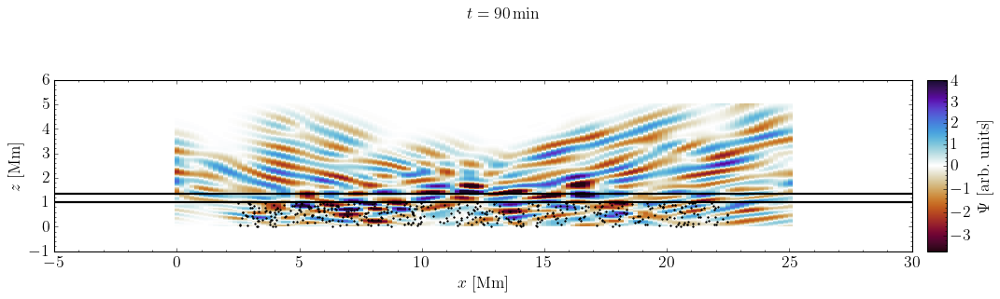

In [8]:
# Display the final wavefield frame and the sampled diagnostic heights.

fig1, ax1, cax1 = make_wide_image_figure()
final_frame_image = ax1.imshow(
    wavefield[:, :, -1],
    origin="lower",
    extent=movie_extent,
    aspect="equal",
    interpolation="nearest",
    cmap=KOMEGA_CMAP,
    norm=movie_norm,
)
ax1.axhline(config.lower_height_Mm, color="k")
ax1.axhline(
    config.lower_height_Mm + config.height_separation_Mm,
    color="k",
    linewidth=2.0,
)
ax1.plot(packets["x0_Mm"], packets["z0_Mm"], "k.", markersize=3)
ax1.set_xlabel(r"$x\ [\mathrm{Mm}]$")
ax1.set_ylabel(r"$z\ [\mathrm{Mm}]$")
add_komega_colorbar(
    fig1, final_frame_image, cax1, r"$\Psi\ [\mathrm{arb.\ units}]$"
)
set_centered_figure_title(
    fig1, rf"$t = {t_s[-1] / 60.0:.3g}\,\mathrm{{min}}$"
)
plt.show()

## Figure 2: sampled horizontal wave numbers and frequencies

## Height extraction, phase differences, and cross-correlation

MATLAB floor(nx/2) is index 64 in one-based indexing, so the corresponding Python reference index is 63. The lower-height reference is cross-correlated with all upper-height locations from that index through the right boundary.

In [9]:
# Extract two height signals and calculate their lagged spectral diagnostics.

height1_target = config.lower_height_Mm
height2_target = config.lower_height_Mm + config.height_separation_Mm
height1_index = int(np.argmin(np.abs(z - height1_target)))
height2_index = int(np.argmin(np.abs(z - height2_target)))
height_difference_Mm = z[height2_index] - z[height1_index]

wv1 = wavefield[height1_index, :, :]
wv2 = wavefield[height2_index, :, :]
reference_index = config.nx // 2 - 1
delta = x[reference_index:] - x[reference_index]

NT = 2048
frequency_mHz = fftshift(fftfreq(NT, d=dt)) * 1000.0
xc_time_minutes = np.arange(-NT // 2, NT // 2) * dt / 60.0

reference_fft = fft(wv1[reference_index, :], n=NT)
upper_fft = fft(wv2[reference_index:, :], n=NT, axis=1)
phase_cross_spectrum = reference_fft[None, :] * np.conj(upper_fft)
pd0 = np.angle(fftshift(phase_cross_spectrum, axes=1)).T
xc0 = fftshift(
    ifft(np.conj(reference_fft)[None, :] * upper_fft, axis=1),
    axes=1,
).T.real

assert wv1.shape == (config.nx, config.nt)
assert pd0.shape == xc0.shape == (NT, delta.size)
print(
    f"height samples: z1={z[height1_index]:.6f} Mm, "
    f"z2={z[height2_index]:.6f} Mm, dz={height_difference_Mm * 1000.0:.3f} km"
)
print(
    f"reference: Python index {reference_index}, MATLAB index {reference_index + 1}, "
    f"x={x[reference_index]:.6f} Mm"
)

height samples: z1=0.998043 Mm, z2=1.350294 Mm, dz=352.250 km
reference: Python index 63, MATLAB index 64, x=12.401575 Mm


In [10]:
# Calculate the cross-spectrum, phase, and power on the padded FFT grid.

NX = 1024

spectrum1 = fft2(wv1, s=(NX, NT))
spectrum2 = fft2(wv2, s=(NX, NT))

cross_spectrum = spectrum1 * np.conj(spectrum2)
phase_2d = np.angle(
    fftshift(cross_spectrum, axes=(0, 1))
)

power1 = fftshift(
    np.abs(fft2(wv1 - wv1.mean(), s=(NX, NT))) ** 2,
    axes=(0, 1),
)

power2 = fftshift(
    np.abs(fft2(wv2 - wv2.mean(), s=(NX, NT))) ** 2,
    axes=(0, 1),
)

kkx = fftshift(fftfreq(NX, d=dx)) * 2.0 * np.pi

assert phase_2d.shape == power1.shape == power2.shape == (NX, NT)

print(
    f"k-omega arrays complete: "
    f"kx=[{kkx[0]:.3f}, {kkx[-1]:.3f}] 1/Mm, "
    f"f=[{frequency_mHz[0]:.3f}, {frequency_mHz[-1]:.3f}] mHz"
)

k-omega arrays complete: kx=[-15.959, 15.928] 1/Mm, f=[-8.241, 8.233] mHz


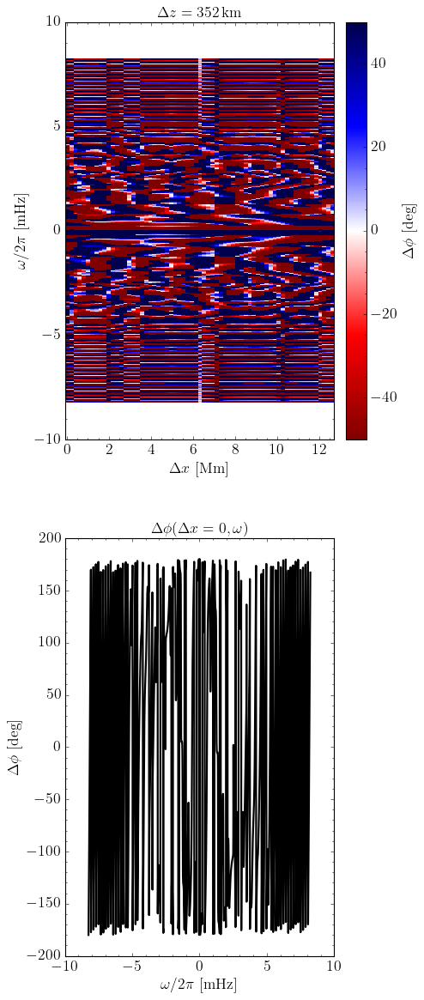

In [11]:
# Plot the frequency-dependent phase differences on the shared diagnostic layout.

phase_degrees = np.rad2deg(pd0)
phase_limit_degrees = np.nanmax(np.abs(phase_degrees))
phase_norm = Normalize(
    vmin=PHASE_DIFFERENCE_LIMITS_DEG[0],
    vmax=PHASE_DIFFERENCE_LIMITS_DEG[1],
)

fig3, axes3, caxes3 = make_centered_stacked_figure()
phase_image = axes3[0].imshow(
    phase_degrees,
    origin="lower",
    extent=regular_grid_extent(delta, frequency_mHz),
    aspect="auto",
    interpolation="nearest",
    cmap="seismic_r",
    norm=phase_norm,
)
axes3[0].set_ylim(*PHASE_DIFFERENCE_LIMITS_MHZ)
axes3[0].set_xlabel(r"$\Delta x\ [\mathrm{Mm}]$")
axes3[0].set_ylabel(r"$\omega/2\pi\ [\mathrm{mHz}]$")
axes3[0].set_title(
    rf"$\Delta z = {height_difference_Mm * 1000.0:.3g}\,\mathrm{{km}}$"
)
add_komega_colorbar(
    fig3, phase_image, caxes3[0], r"$\Delta\phi\ [\mathrm{deg}]$"
)

axes3[1].plot(frequency_mHz, phase_degrees[:, 0], "k")
axes3[1].set_xlim(*PHASE_DIFFERENCE_LIMITS_MHZ)
axes3[1].set_title(r"$\Delta\phi(\Delta x=0,\omega)$")
axes3[1].set_xlabel(r"$\omega/2\pi\ [\mathrm{mHz}]$")
axes3[1].set_ylabel(r"$\Delta\phi\ [\mathrm{deg}]$")
caxes3[1].set_visible(False)
plt.show()

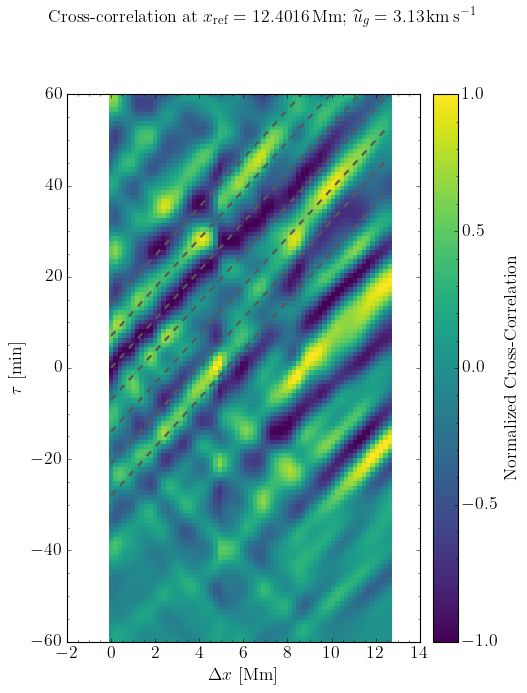

In [12]:
# Normalize the lagged cross-correlation and overlay the packet group-speed reference.

median_group_speed = np.median(packets["group_speed_Mm_s"])
xc_scale = np.nanmax(np.abs(xc0), axis=0, keepdims=True)
xc_display = np.divide(
    xc0,
    xc_scale,
    out=np.zeros_like(xc0),
    where=xc_scale > 0.0,
)
xc_norm = Normalize(vmin=-1.0, vmax=1.0)

fig55, ax55, cax55 = make_centered_single_panel_figure()
xc_image = ax55.imshow(
    xc_display,
    origin="lower",
    extent=regular_grid_extent(delta, xc_time_minutes),
    aspect="auto",
    interpolation="nearest",
    cmap="viridis",
    norm=xc_norm,
)
for offset_minutes in (-28.0, -21.0, -14.0, -7.0, 0.0, 7.0, 14.0):
    ax55.plot(
        delta,
        delta / median_group_speed / 60.0 + offset_minutes,
        color="0.35",
        linestyle="--",
        linewidth=2.0,
    )
ax55.set_ylim(*CROSS_CORRELATION_LIMITS_MIN)
ax55.set_xlabel(r"$\Delta x\ [\mathrm{Mm}]$")
ax55.set_ylabel(r"$\tau\ [\mathrm{min}]$")
add_komega_colorbar(
    fig55, xc_image, cax55, "Normalized Cross-Correlation"
)
set_centered_figure_title(
    fig55,
    rf"Cross-correlation at $x_{{\mathrm{{ref}}}} = {x[reference_index]:g}\,\mathrm{{Mm}}$; "
    rf"$\widetilde{{u}}_g = {median_group_speed * 1000.0:.3g}\,\mathrm{{km\,s^{{-1}}}}$",
)
plt.show()

## Verification summary

In [13]:
# Verify panel dimensions, axis styles, and retained figure title formatting.

math_titles = (
    movie_title.get_text(),
    fig1._suptitle.get_text(),
    fig2._suptitle.get_text(),
    axes3[0].get_title(),
    axes3[1].get_title(),
    fig55._suptitle.get_text(),
    fig6._suptitle.get_text(),
    axes7[0].get_title(),
    axes7[1].get_title(),
)
spectral_axes = (ax2, *axes3, ax55, ax6, *axes7)
komega_axes = (ax2, ax6, *axes7)


def panel_size_inches(figure, axis):
    '''
    Purpose
    -------
    Measure a plotted axes box in physical figure units.

    Inputs
    ------
    figure: matplotlib.figure.Figure
        Figure supplying its width/height in inches.

    axis: matplotlib.axes.Axes
        Axes whose normalized position is measured.

    Outputs
    -------
    width, height: tuple of float
        Axes dimensions in inches.
    '''

    position = axis.get_position()
    figure_width, figure_height = figure.get_size_inches()
    return position.width * figure_width, position.height * figure_height


populated_figures = {
    "movie_figure": len(movie_axis.images) == 1,
    "fig1": len(ax1.images) == 1,
    "fig2": len(ax2.images) == 1 and len(ax2.lines) > 0,
    "fig3": len(axes3[0].images) == 1 and len(axes3[1].lines) == 1,
    "fig55": len(ax55.images) == 1,
    "fig6": len(ax6.images) == 1 and len(ax6.lines) > 0,
    "fig7": all(len(axis.images) == 1 for axis in axes7),
}

colorbar_pairs = (
    (movie_image, movie_colorbar_axis),
    (final_frame_image, cax1),
    (filter_image, cax2),
    (phase_image, caxes3[0]),
    (xc_image, cax55),
    (phase2d_image, cax6),
    (power1_image, caxes7[0]),
    (power2_image, caxes7[1]),
)

checks = {
    "wavefield_shape": wavefield.shape == (512, 128, 90),
    "lower_height_index": height1_index == 102,
    "upper_height_index": height2_index == 138,
    "reference_index": reference_index == 63,
    "separation_count": delta.size == 65,
    "phase_shape": pd0.shape == (2048, 65),
    "komega_shape": phase_2d.shape == (1024, 2048),
    "external_latex_enabled": mpl.rcParams["text.usetex"] is True,
    "math_titles_delimited": all(
        title.count("$") >= 2 and title.count("$") % 2 == 0
        for title in math_titles
    ),
    "komega_panel_aspect": all(
        np.isclose(axis.get_box_aspect(), TARGET_PANEL_BOX_ASPECT)
        for axis in spectral_axes
    ),
    "figures_populated": all(populated_figures.values()),
    "colorbars_attached": all(
        image.colorbar is not None and image.colorbar.ax is colorbar_axis
        for image, colorbar_axis in colorbar_pairs
    ),
    "komega_limits": all(
        np.allclose(axis.get_xlim(), KOMEGA_K_LIMITS)
        and np.allclose(axis.get_ylim(), KOMEGA_FREQUENCY_LIMITS_MHZ)
        for axis in komega_axes
    ),
    "komega_colormaps": (
        filter_image.get_cmap().name == "viridis"
        and phase2d_image.get_cmap().name == KOMEGA_CMAP.name
        and power1_image.get_cmap().name == KOMEGA_CMAP.name
        and power2_image.get_cmap().name == KOMEGA_CMAP.name
    ),
    "komega_phase_norm": np.allclose(
        (phase_2d_norm.vmin, phase_2d_norm.vcenter, phase_2d_norm.vmax),
        KOMEGA_PHASE_NORM,
    ),
    "diagnostic_display_ranges": (
        np.allclose((phase_norm.vmin, phase_norm.vmax), PHASE_DIFFERENCE_LIMITS_DEG)
        and np.allclose(axes3[0].get_ylim(), PHASE_DIFFERENCE_LIMITS_MHZ)
        and np.allclose(ax55.get_ylim(), CROSS_CORRELATION_LIMITS_MIN)
        and np.allclose((xc_norm.vmin, xc_norm.vmax), (-1.0, 1.0))
    ),
    "phase_model_curves_black": len(ax6.lines) > 0 and all(
        line.get_color() in ("k", "black", "#000000") for line in ax6.lines
    ),
    "phase_model_has_no_legend": ax6.get_legend() is None,
    "phase_model_identified_in_title": (
        "Newington" in phase_title.get_text()
        and all(symbol in phase_title.get_text() for symbol in ("c_s", "Delta z", "theta", "phi"))
    ),
    "power_panels_large": all(
        width >= 3.8 and height >= 6.0
        for width, height in (panel_size_inches(fig7, axis) for axis in axes7)
    ),
    "diagnostic_panels_large": all(
        width >= 3.8 and height >= 6.0
        for width, height in (
            *(panel_size_inches(fig3, axis) for axis in axes3),
            panel_size_inches(fig55, ax55),
            panel_size_inches(fig6, ax6),
        )
    ),
    "height_extraction_panels_large": all(
        width >= 11.0 and height >= 2.2 and width * height >= 24.0
        for width, height in (
            panel_size_inches(movie_figure, movie_axis),
            panel_size_inches(fig1, ax1),
        )
    ),
    "finite_outputs": all(
        np.all(np.isfinite(array))
        for array in (wavefield, pd0, xc0, phase_2d, power1, power2)
    ),
}
if not all(checks.values()):
    raise AssertionError({name: passed for name, passed in checks.items() if not passed})

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL':4s}  {name}")
print("\nAll active MATLAB outputs were generated successfully.")

NameError: name 'fig2' is not defined

# 1 Wavefield, tweak one parameter and calculate their phase-differences relative to each other

In [ ]:
# Define complex-wave and phase-folding helpers with their actual mathematical contracts.

def wavefunction(x_m, t_s, amplitude, k_h_rad_m, omega_rad_s):
    
    '''
    Purpose
    -------
    Evaluate the complex plane wave amplitude*exp(i*(k_h*x - omega*t)).

    Inputs
    ------
    x_m: array-like
        Horizontal position in meters.

    t_s: array-like
        Time in seconds.

    amplitude: float or complex
        Wave amplitude in the chosen field units.

    k_h_rad_m: float
        Horizontal angular wavenumber in rad/m.

    omega_rad_s: float
        Angular frequency in rad/s.

    Outputs
    -------
    wavefield: np.ndarray
        Complex wave values with the broadcast position/time shape and
        amplitude units.

    Author(s)
    ---------
    Julio M. Morales, Sept 27th, 2026
    '''
       
    # Calculate the phase of the wavefunction based on the provided parameters. 
    phase_rad = k_h_rad_m * x_m - omega_rad_s * t_s
    
    return amplitude * np.exp(1j * phase_rad)


def fold_phase_degrees(phase_degrees):
    
    '''
    Purpose
    -------
    Continuously fold phase through the implemented 2*arcsin(sin(phase)) mapping.

    Inputs
    ------
    phase_degrees: array-like
        Input phase in degrees.

    Outputs
    -------
    folded: np.ndarray
        Degree values in [-180, 180] with the input shape. The implemented
        mapping doubles the arcsine result; it is distinct from ordinary
        modulo wrapping of a phase angle.

    Author(s)
    ---------
    Julio M. Morales, Sept 27th, 2026
    '''

    # Wrap the phase into [-180, 180] degrees using the sine function.    
    phase_radians = np.deg2rad(np.asarray(phase_degrees))
    
    return np.rad2deg(2.0 * np.arcsin(np.sin(phase_radians)))


def phase_difference(wavefield_1, wavefield_2):
    
    '''
    Purpose
    -------
    Apply the continuous folding map to arg(wavefield_1*conj(wavefield_2)).

    Inputs
    ------
    wavefield_1, wavefield_2: array-like, complex
        Broadcast-compatible complex wavefields at the two sampled positions/heights.

    Outputs
    -------
    phase_degrees: np.ndarray
        Folded phase differences in degrees using fold_phase_degrees().

    Author(s)
    ---------
    Julio M. Morales, Sept 27th, 2026
    '''
    
    # Calculate the wrapped phase difference in degrees using the angle of the product of wavefield_1 and the complex conjugate of wavefield_2.
    wrapped_phase_degrees = np.angle(wavefield_1 * np.conj(wavefield_2), deg=True)
    
    return fold_phase_degrees(wrapped_phase_degrees)

In [14]:
# Load simulation coordinate arrays while keeping large field variables lazy.

import xarray as xr
# import the Path class from pathlib to handle file paths
from pathlib import Path

# Download the simulation
simulation_path = Path("/Users/juliomorales/Library/CloudStorage/GoogleDrive-juliomorales1823@gmail.com/My Drive/Graduate School/Research/Projects/Helioseismology/Morales_2025a/Data/co5bold/hx/10G/""simulation_hx_10G_33570s_48000s.nc")

# Load only the coordinate arrays; the multi-gigabyte field variables remain lazy.
with xr.open_dataset(simulation_path) as simulation:
    simulation_time_s = simulation["time"].values.astype(float)
    simulation_x_cm = simulation["xc1"].values.astype(float)

# The file stores absolute simulation time in seconds and x cell centers in cm.
# Use elapsed time for the wave phase so the first snapshot defines t = 0.
time_elapsed_s = simulation_time_s - simulation_time_s[0]
time_elapsed_min = time_elapsed_s / 60.0
x_m = simulation_x_cm * 1.0e-2
x_Mm = simulation_x_cm * 1.0e-8
X_m, T_s = np.meshgrid(x_m, time_elapsed_s, indexing="xy")

dx_m = np.median(np.diff(x_m))
dt_s = np.median(np.diff(simulation_time_s))

# Print the results
print(
    f"Loaded {simulation_path.name}: "
    f"nt={time_elapsed_s.size}, nx={x_m.size}, "
    f"dt={dt_s:g} s, dx={dx_m / 1.0e6:g} Mm")

Loaded simulation_hx_10G_33570s_48000s.nc: nt=482, nx=240, dt=30 s, dx=0.16 Mm


In [15]:
# Compare the configured waves, which differ in both wavenumber and frequency.

# The two waves differ only in horizontal wavenumber.
amplitude = 4.5  # km/s
omega_1_rad_s = 2.5 * 2.0*np.pi*1.0e-3
omega_2_rad_s = 0.9*omega_1_rad_s
k_h_1_rad_m = 3.0e-6  # Mm^{-1} -> m^{-1}
k_h_2_rad_m = 0.5*k_h_1_rad_m  # Mm^{-1} -> m^{-1}

wavefield_1_complex = wavefunction(X_m, T_s, amplitude, k_h_1_rad_m, omega_1_rad_s)
wavefield_2_complex = wavefunction(X_m, T_s, amplitude, k_h_2_rad_m, omega_2_rad_s)
wavefield_1 = wavefield_1_complex.real
wavefield_2 = wavefield_2_complex.real
delta_phi_deg = phase_difference(wavefield_1_complex, wavefield_2_complex)

# Use the simulation cadence and duration to define the frequency grid.
simulation_frequency_mHz = (np.fft.fftshift(np.fft.fftfreq(time_elapsed_s.size, d=dt_s)) * 1.0e3)

# Numerically calculate one spatial phase-difference row at every frequency.
delta_phi_frequency_deg = np.empty((simulation_frequency_mHz.size, x_m.size))
for frequency_index, frequency_mHz_i in enumerate(simulation_frequency_mHz):
    omega_rad_s_i = 2.0 * np.pi * frequency_mHz_i * 1.0e-3
    frequency_wavefield_1 = wavefunction(X_m, T_s, amplitude, k_h_1_rad_m, omega_rad_s_i)
    frequency_wavefield_2 = wavefunction(X_m, T_s, amplitude, k_h_2_rad_m, omega_rad_s_i)
    mean_phase_vector = np.mean(frequency_wavefield_1 * np.conj(frequency_wavefield_2), axis=0)
    delta_phi_frequency_deg[frequency_index] = np.angle(mean_phase_vector, deg=True)
delta_phi_frequency_deg = fold_phase_degrees(delta_phi_frequency_deg)

wavefield_norm = TwoSlopeNorm(vmin=-amplitude, vcenter=0.0, vmax=amplitude)
phase_difference_norm = TwoSlopeNorm(vmin=-180.0, vcenter=0.0, vmax=180.0)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, constrained_layout=True)

wave_1_image = axes[0].pcolormesh(x_Mm, time_elapsed_min, wavefield_1, shading="auto", cmap="seismic", norm=wavefield_norm)
wave_2_image = axes[1].pcolormesh(x_Mm, time_elapsed_min, wavefield_2, shading="auto", cmap="seismic", norm=wavefield_norm,)
phase_difference_image = axes[2].pcolormesh(x_Mm, simulation_frequency_mHz, delta_phi_frequency_deg, shading="auto", cmap="seismic", norm=phase_difference_norm)

axes[0].set_title(rf"Wave 1: $k_h={k_h_1_rad_m:.2g}\,\mathrm{{rad\,m^{{-1}}}}$")
axes[1].set_title(rf"Wave 2: $k_h={k_h_2_rad_m:.2g}\,\mathrm{{rad\,m^{{-1}}}}$")
axes[2].set_title(r"Numerical phase difference $\arg(\psi_1\psi_2^*)$")
for axis in axes:
    axis.set_xlabel(r"$x$ [Mm]")
    axis.set_xlim(x_Mm[0], x_Mm[-1])
axes[0].set_ylabel(r"Elapsed simulation time [min]")
axes[0].set_ylim(time_elapsed_min[0], time_elapsed_min[-1])
axes[1].set_ylim(time_elapsed_min[0], time_elapsed_min[-1])
axes[2].set_ylabel(r"Frequency [mHz]")
axes[2].set_ylim(0.0, 5.0)
axes[2].set_xlim(0.0, 10.0)
fig.colorbar(wave_1_image, ax=axes[:2], label=r"$\mathrm{Re}(\psi)$ [km s$^{-1}$]")
fig.colorbar(phase_difference_image, ax=axes[2], label=r"$\Delta\phi$ [deg]")
plt.show()

NameError: name 'wavefunction' is not defined

In [16]:
# Compare the numerical folded cross-product phase with the analytic expression.

# Verify the numerical cross-product phase against the analytic result.
analytic_phase_rad = ((k_h_1_rad_m - k_h_2_rad_m) * X_m - (omega_1_rad_s - omega_2_rad_s) * T_s)
analytic_phase_deg = fold_phase_degrees(np.angle(np.exp(1j * analytic_phase_rad), deg=True))

# Plot the analytic phase difference for comparison.
analytic_phase_image = plt.pcolormesh(x_Mm, time_elapsed_min, analytic_phase_deg, shading="auto", cmap="seismic", norm=phase_difference_norm,)
plt.title(r"Analytic phase difference $\arg(\psi_1\psi_2^*)$")
plt.xlabel(r"$x$ [Mm]")
plt.ylabel(r"Elapsed simulation time [min]")
plt.xlim(x_Mm[0], 10.0)
plt.ylim(time_elapsed_min[0], time_elapsed_min[-1])
plt.colorbar(label=r"$\Delta\phi$ [deg]")
plt.show()

NameError: name 'fold_phase_degrees' is not defined

In [17]:
# Define the native-profile WKB integrals and dense profile evaluator.

from pathlib import Path
import h5py
import numpy as np
from scipy.integrate import trapezoid, cumulative_trapezoid

PROFILE_DIR = Path(
    '/Users/juliomorales/Research/Projects/Morales_2025a/'
    'Data/co5bold/co5bold_1d_profiles'
)


def _wkb_profile(kh, omega, profile_file, heights, H):
    '''
    Purpose
    -------
    Read the nearest native profile interval and validate a single-sign WKB branch.

    Inputs
    ------
    kh: float
        Horizontal angular wavenumber in rad/km.

    omega: float
        Positive angular frequency in rad/s.

    profile_file: str or Path
        Profile path resolved beneath PROFILE_DIR unless absolute.

    heights: sequence of float
        Requested sample heights in km.

    H: float
        Positive density scale height in km.

    Outputs
    -------
    z, q, selected_heights: tuple of np.ndarray
        Selected native heights (km), kz_squared (km^-2), and nearest heights
        corresponding to the requested endpoints. Reject invalid grids/inputs,
        out-of-range heights, nonfinite profiles, and sampled turning points.
    '''
    if not np.isfinite([kh, omega, H, *heights]).all() or omega <= 0 or H <= 0:
        raise ValueError('Inputs must be finite; omega and H must be positive.')
    with h5py.File(PROFILE_DIR / Path(profile_file).expanduser(), 'r') as f:
        z, cs, N = [np.asarray(f[key], float) for key in('z', 'sound_speed', 'brunt_vaisala_freq')]
    z, cs = z / 1e5, cs / 1e5  # Legacy cm and cm/s -> km and km/s.
    if not np.isfinite(z).all() or not np.all(np.diff(z) > 0):
        raise ValueError('Profile heights must be finite and strictly increasing.')
    if min(heights) < z[0] or max(heights) > z[-1]:
        raise ValueError(f'Heights must lie in [{z[0]:g}, {z[-1]:g}] km.')
    # Select nearest native endpoints and retain the complete intervening interval
    indices = [np.argmin(abs(z - h)) for h in heights]
    selected_heights = z[indices]
    selection = slice(min(indices), max(indices) + 1)
    z, cs, N = z[selection], cs[selection], N[selection]
    if not np.isfinite([cs, N]).all() or np.any(cs <= 0):
        raise ValueError('The selected interval contains invalid cs or N values.')
    # Require a finite kz_squared profile with one strict sign across the interval
    q = N**2 * kh**2 / omega**2 + omega**2 / cs**2 - 1 / (4 * H**2) - kh**2
    if not np.isfinite(q).all() or not (np.all(q > 0) or np.all(q < 0)):
        raise ValueError('Invalid kz_squared or a sampled WKB turning point.')
    return z, q, selected_heights


def wkb_vertical_velocity(kh, omega, height, profile_file, *, reference_height, H=125.0):
    '''
    Purpose
    -------
    Evaluate the unnormalized WKB profile at the nearest requested height.

    Inputs
    ------
    kh: float
        Horizontal angular wavenumber in rad/km.

    omega: float
        Positive angular frequency in rad/s.

    height, reference_height: float
        Evaluation and phase-reference heights in km.

    profile_file: str or Path
        Atmospheric profile path interpreted by _wkb_profile.

    H: float, optional
        Positive density scale height in km.

    Outputs
    -------
    W: float
        abs(kz_squared)**(-1/4) times cos(integrated wavenumber) for the
        propagating branch or exp(integrated absolute wavenumber) otherwise.
        Coefficients are fixed at c1=1, c2=0; no physical velocity normalization
        is supplied. Native-profile validation and overflow errors propagate.
    '''
    z, q, endpoints = _wkb_profile(kh, omega, profile_file, (reference_height, height), H)
    if endpoints[1] < endpoints[0]:
        z, q = z[::-1], q[::-1]
    # Integrate in the chosen reference-to-height direction
    phase = trapezoid(np.sqrt(abs(q)), x=z)
    with np.errstate(over='raise', invalid='raise'):
        return float(abs(q[-1])**(-0.25) * (np.cos(phase) if q[-1] > 0 else np.exp(phase)))


def wkb_vertical_velocity_profile(
    kh, omega, profile_file, *, height_min, height_max,
    reference_height, H=125.0, n_z=4000, samples_per_scale=64,
):
    '''
    Purpose
    -------
    Build a dense WKB profile by interpolating native kz_squared within one branch.

    Inputs
    ------
    kh: float
        Horizontal angular wavenumber in rad/km.

    omega: float
        Positive angular frequency in rad/s.

    profile_file: str or Path
        Atmospheric profile path interpreted by _wkb_profile.

    height_min, height_max, reference_height: float
        Distinct ordered profile bounds and an included phase-reference height, in km.

    H: float, optional
        Positive density scale height in km.

    n_z: int, optional
        Minimum dense-grid count, at least two.

    samples_per_scale: int, optional
        Minimum samples per local wavelength or evanescence scale, at least two.

    Outputs
    -------
    grid, W: tuple of np.ndarray
        Dense heights in km and the unnormalized WKB amplitude. The grid
        includes native heights; the phase is zero at the nearest reference
        sample. Requests requiring over two million samples raise ValueError.
    '''
    if not height_min <= reference_height <= height_max or height_min >= height_max:
        raise ValueError('Require height_min <= reference_height <= height_max, with distinct limits.')
    if any(not isinstance(n, (int, np.integer)) or n < 2 for n in (n_z, samples_per_scale)):
        raise ValueError('Grid counts must be integers of at least 2.')
    z, q, endpoints = _wkb_profile(kh, omega, profile_file, (height_min, height_max, reference_height), H)
    if z.size < 2:
        raise ValueError('Plot limits select the same native height.')
    # Increase dense sampling to resolve the shortest local wavelength/decay scale
    scale = (2 * np.pi if q[0] > 0 else 1.0) / np.sqrt(np.max(abs(q)))
    n_z = max(n_z, int(np.ceil((z[-1] - z[0]) * samples_per_scale / scale)) + 1)
    if n_z > 2_000_000:
        raise ValueError('Resolving this interval requires over 2 million points.')
    grid = np.unique(np.r_[np.linspace(z[0], z[-1], n_z), z])
    # Interpolate kz_squared and integrate phase relative to the selected native reference
    q = np.interp(grid, z, q)
    phase = cumulative_trapezoid(np.sqrt(abs(q)), x=grid, initial=0.0)
    phase -= phase[np.searchsorted(grid, endpoints[2])]
    with np.errstate(over='raise', invalid='raise'):
        W = abs(q)**(-0.25) * (np.cos(phase) if q[0] > 0 else np.exp(phase))
    return grid, W


In [18]:
# Load atmospheric profiles through the shared production pipeline.

# The profile diagnostic is shared with the production time_distance pipeline.
import sys
time_distance_dir = Path("/Users/juliomorales/Library/CloudStorage/GoogleDrive-juliomorales1823@gmail.com/My Drive/Graduate School/Research/Projects/Helioseismology/Morales_2025a/Code/Time-Distance")
if str(time_distance_dir) not in sys.path:
    sys.path.insert(0, str(time_distance_dir))
from atmospheric_profiles import load_profiles, save_diagnostic
from pipeline import load_config_module
import copy
profile_config = copy.deepcopy(load_config_module(time_distance_dir / "config.py").config)
profile_config["data"]["file"] = str(Path("/Users/juliomorales/Library/CloudStorage/GoogleDrive-juliomorales1823@gmail.com/My Drive/Graduate School/Research/Projects/Helioseismology/Morales_2025a/Data/co5bold/hx/10G/simulation_hx_10G_33570s_48000s.nc"))
atmospheric_profiles = load_profiles(profile_config)


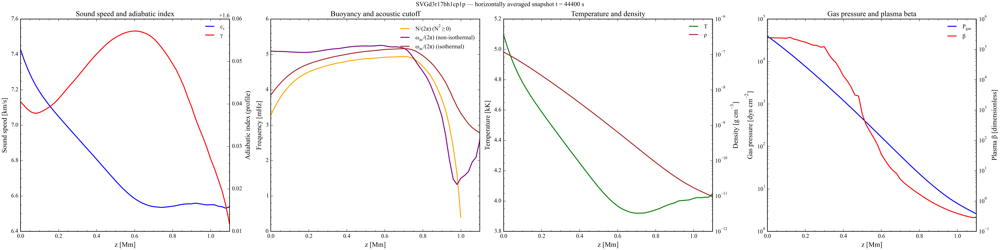

In [19]:
# Render the shared atmospheric-profile diagnostic using native coordinates.

# Native coordinates; four panels share the simulation height range.
# Source speeds are cm/s; angular frequencies are rad/s.
import importlib
import atmospheric_profiles as atmospheric_profile_module
save_diagnostic = importlib.reload(atmospheric_profile_module).save_diagnostic
profile_figures = save_diagnostic(atmospheric_profiles, profile_config["paths"]["figure_dir"])
from IPython.display import Image
display(Image(filename=str(next(path for path in profile_figures if path.suffix == ".png"))))


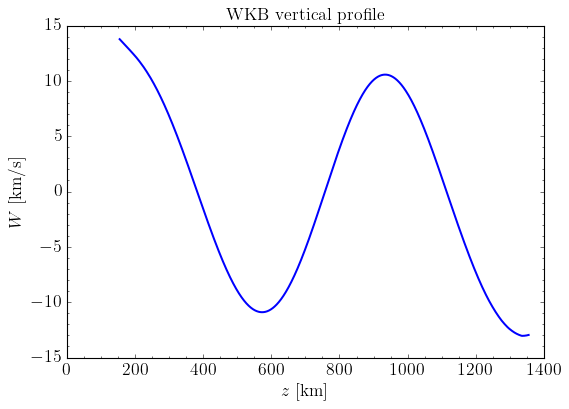

In [20]:
# Plot the configured unnormalized WKB profile on its selected height interval.

# Same horizontal-10 G profile; heights are in km from its native origin.
wkb_z_km, wkb_W = wkb_vertical_velocity_profile(kh=3.0 / 1000.0, omega=2 * np.pi * 2.5e-3, profile_file="SVGd3r17bh1cp1p_t00044400s_atmos_param.h5", height_min=1500, height_max=2700, reference_height=1500)
wkb_figure, wkb_axis = plt.subplots(figsize=(7, 5), constrained_layout=True)
wkb_axis.plot(wkb_z_km - np.max(wkb_z_km)/2, wkb_W, linewidth=1.8)
wkb_axis.set(xlabel=r"$z$ [km]", ylabel=r"$W$ [km/s]", title="WKB vertical profile")
wkb_axis.minorticks_on()
wkb_axis.tick_params(which="both", direction="in", top=True, right=True)
plt.show()


In [21]:
# Compare spectra only after confirming their wavenumber/frequency axes agree.

import cmasher as cmr
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import TwoSlopeNorm

z0, k_z0, nu_z0 = spectra["z0"]
hx, k_hx, nu_hx = spectra["hx100G"]

if not (np.array_equal(k_z0, k_hx) and np.array_equal(nu_z0, nu_hx)):
    raise ValueError("The spectra have different k or frequency axes.")

difference = hx - z0

fig, axes = plt.subplots(1, 3, figsize=(14, 7))
fig.subplots_adjust(left=0.06, right=0.94, bottom=0.12, top=0.90, wspace=0.55)

panels = [
    (z0, "z0, 0–440 km (unfiltered)", r"$\Delta\phi$ [deg]"),
    (hx, "hx100G, 0–440 km (unfiltered)", r"$\Delta\phi$ [deg]"),
    (
        difference,
        "Difference (hx100G − z0)",
        r"$\Delta\phi_{\mathrm{hx100G}}-\Delta\phi_{\mathrm{z0}}$ [deg]",
    ),
]

for ax, (values, title, colorbar_label) in zip(axes, panels):
    mesh = ax.pcolormesh(
        k_z0, nu_z0, values.T,
        shading="auto",
        cmap=cmr.fusion,
        norm=TwoSlopeNorm(vmin=-80, vcenter=0, vmax=80),
    )

    ax.set(
        xlim=(0, 7),
        ylim=(0, 10),
        xlabel=r"$k_h$ [Mm$^{-1}$]",
        ylabel=r"$\nu / 2\pi$ [mHz]",
        title=title,
    )
    ax.set_box_aspect(1.55)

    # Coordinates relative to the plot: colorbar matches its exact height.
    cax = ax.inset_axes([1.05, 0, 0.045, 1])
    fig.colorbar(
        mesh,
        cax=cax,
        label=colorbar_label,
        ticks=np.arange(-80, 81, 20),
    )

plt.show()

NameError: name 'spectra' is not defined

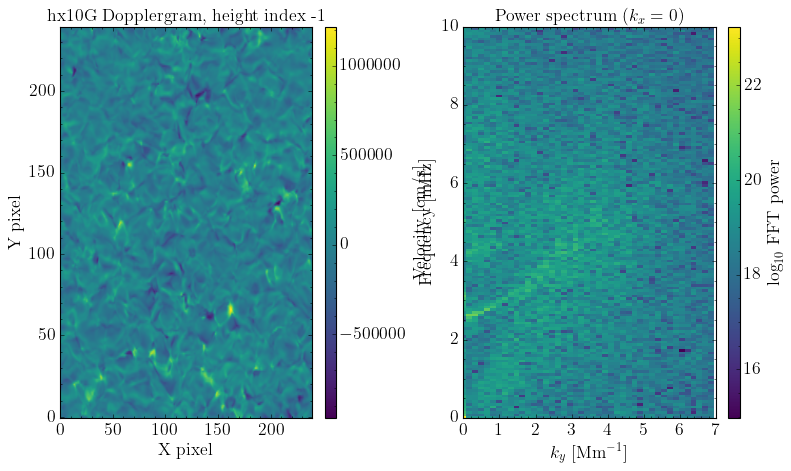

In [ ]:
# Load the selected simulation slice and display its configured field diagnostics.

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

data_path = (
    "/Users/juliomorales/Research/Projects/Morales_2025a/"
    "Data/co5bold/hx/10G/simulation_hx_10G_33570s_48000s.nc"
)

height_index = -1
time_index = 0

with xr.open_dataset(data_path, engine="netcdf4") as data:
    # Extract the full time series at one height: [time, y, x].
    v3_velocity = (
        data["v3"]
        .isel(xc3=height_index)
        .transpose("time", "xc2", "xc1")
        .values.astype(np.float32)
    )

    dt = float(np.median(np.diff(data["time"].values)))         # seconds
    dy = float(np.median(np.diff(data["xc2"].values))) / 1e8    # cm → Mm
    velocity_units = data["v3"].attrs.get("units", "")

v3_dopplergram = v3_velocity[time_index]

# Three-dimensional FFT over time, y, and x.
fft_velocity = np.fft.fftshift(
    np.fft.fftn(v3_velocity),
    axes=(0, 1, 2),
)
power_spectrum = np.abs(fft_velocity) ** 2

nt, ny, nx = v3_velocity.shape
frequency = np.fft.fftshift(np.fft.fftfreq(nt, d=dt)) * 1e3
ky = np.fft.fftshift(np.fft.fftfreq(ny, d=dy)) * 2 * np.pi

# Preserve the original central kx = 0 slice: [frequency, ky].
power_slice = power_spectrum[:, :, nx // 2]

# Crop to the same displayed ranges as the three-panel plots.
frequency_mask = (frequency >= 0) & (frequency <= 10)
ky_mask = (ky >= 0) & (ky <= 7)
cropped_power = power_slice[np.ix_(frequency_mask, ky_mask)]

log_power = np.log10(
    np.maximum(cropped_power, np.finfo(cropped_power.dtype).tiny)
)

fig, axes = plt.subplots(1, 2, figsize=(10, 7))
fig.subplots_adjust(
    left=0.08, right=0.90, bottom=0.12, top=0.90, wspace=0.60
)

# Dopplergram
im = axes[0].imshow(
    v3_dopplergram,
    origin="lower",
    cmap="viridis",
    aspect="auto",
)
axes[0].set(
    title=f"hx10G Dopplergram, height index {height_index}",
    xlabel="X pixel",
    ylabel="Y pixel",
)

# Power spectrum at kx = 0
im2 = axes[1].pcolormesh(
    ky[ky_mask],
    frequency[frequency_mask],
    log_power,
    shading="auto",
    cmap="viridis",
)
axes[1].set(
    title=r"Power spectrum ($k_x=0$)",
    xlabel=r"$k_y$ [Mm$^{-1}$]",
    ylabel="Frequency [mHz]",
    xlim=(0, 7),
    ylim=(0, 10),
)

velocity_label = f"Velocity [{velocity_units}]" if velocity_units else "Velocity"

for ax, image, label in zip(
    axes,
    (im, im2),
    (velocity_label, r"$\log_{10}$ FFT power"),
):
    ax.set_box_aspect(1.55)
    cax = ax.inset_axes([1.05, 0, 0.045, 1])
    fig.colorbar(image, cax=cax, label=label)

plt.show()

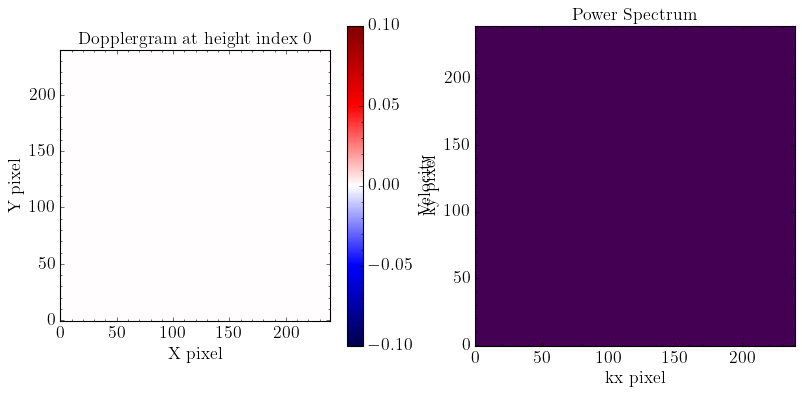